In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

churn = pd.read_csv("../data/processed/churn_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", churn.shape)

churn.head()

Dataset loaded successfully!
Shape: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
churn["Age_Group"] = pd.cut(
    churn["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

churn["Activity_Status"] = churn["IsActiveMember"].map({
    0: "Inactive",
    1: "Active"
})

churn["Product_Group"] = churn["NumOfProducts"].apply(
    lambda x: "1 Product" if x == 1
    else "2 Products" if x == 2
    else "3+ Products"
)

churn[[
    "Age",
    "Age_Group",
    "Activity_Status",
    "NumOfProducts",
    "Product_Group",
    "Exited"
]].head(10)

,Age,Age_Group,Activity_Status,NumOfProducts,Product_Group,Exited
0,42,36-45,Active,1,1 Product,1
1,41,36-45,Active,1,1 Product,0
2,42,36-45,Inactive,3,3+ Products,1
3,39,36-45,Inactive,2,2 Products,0
4,43,36-45,Active,1,1 Product,0
5,44,36-45,Inactive,2,2 Products,1
6,50,46-55,Active,2,2 Products,0
7,29,26-35,Inactive,4,3+ Products,1
8,44,36-45,Active,2,2 Products,0
9,27,26-35,Active,1,1 Product,0


In [3]:
churn_profiles = churn.groupby(
    ["Age_Group", "Activity_Status", "Product_Group"],
    observed=True
).agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

churn_profiles["Churn_Rate"] = (
    churn_profiles["Churn_Rate"] * 100
).round(2)

churn_profiles = churn_profiles[
    churn_profiles["Total_Customers"] >= 50
]

churn_profiles = churn_profiles.sort_values(
    by="Churn_Rate",
    ascending=False
).reset_index(drop=True)

churn_profiles

,Age_Group,Activity_Status,Product_Group,Total_Customers,Churned_Customers,Churn_Rate
0,56+,Inactive,1 Product,141,129,91.49
1,36-45,Active,3+ Products,50,44,88.00
2,36-45,Inactive,3+ Products,80,69,86.25
3,46-55,Inactive,1 Product,439,323,73.58
4,46-55,Active,1 Product,358,165,46.09
5,36-45,Inactive,1 Product,966,312,32.30
6,46-55,Inactive,2 Products,178,52,29.21
7,56+,Active,1 Product,306,64,20.92
8,36-45,Active,1 Product,892,172,19.28
9,26-35,Inactive,1 Product,845,139,16.45


In [4]:
customer_comparison = churn.groupby("Exited").agg(
    Total_Customers=("Exited", "count"),
    Average_Age=("Age", "mean"),
    Median_Age=("Age", "median"),
    Average_Credit_Score=("CreditScore", "mean"),
    Average_Balance=("Balance", "mean"),
    Average_Tenure=("Tenure", "mean"),
    Average_Products=("NumOfProducts", "mean"),
    Average_Salary=("EstimatedSalary", "mean")
).reset_index()

customer_comparison["Exited"] = customer_comparison["Exited"].map({
    0: "Retained",
    1: "Churned"
})

customer_comparison = customer_comparison.round(2)

customer_comparison

,Exited,Total_Customers,Average_Age,Median_Age,Average_Credit_Score,Average_Balance,Average_Tenure,Average_Products,Average_Salary
0,Retained,7963,37.41,36.0,651.85,72745.30,5.03,1.54,99738.39
1,Churned,2037,44.84,45.0,645.35,91108.54,4.93,1.48,101465.68


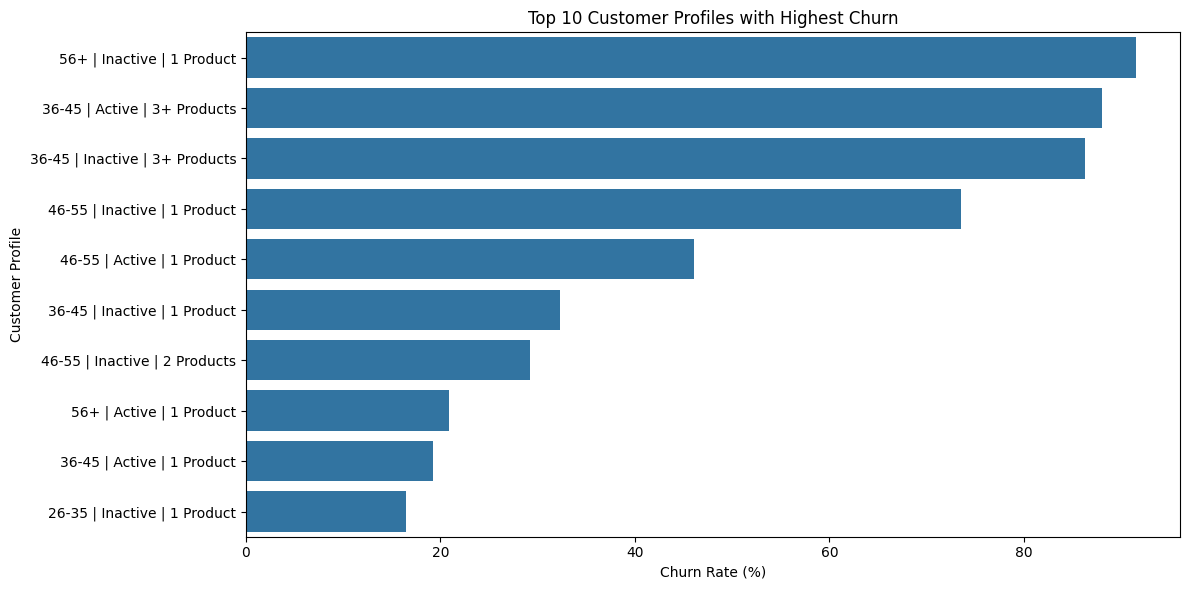

In [6]:
top_profiles = churn_profiles.head(10).copy()

top_profiles["Customer_Profile"] = (
    top_profiles["Age_Group"].astype(str)
    + " | "
    + top_profiles["Activity_Status"]
    + " | "
    + top_profiles["Product_Group"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_profiles,
    x="Churn_Rate",
    y="Customer_Profile"
)

plt.title("Top 10 Customer Profiles with Highest Churn")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Profile")
plt.tight_layout()
plt.show()

In [5]:
churn_profiles.to_csv(
    "../data/processed/churn_combined_profiles.csv",
    index=False
)

customer_comparison.to_csv(
    "../data/processed/churned_vs_retained.csv",
    index=False
)

print("Churn analysis files saved successfully!")

Churn analysis files saved successfully!
